Analyze time-series fluorescence data from PURE (Protein synthesis Using Recombinant Elements) experiments. 

## Setup 

In [1]:
%load_ext autoreload
%autoreload 2
    
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Import the cdk platereader module
from cdk.analysis.cytosol import platereader as pr

# Set up plotting
pr.plot_setup()

## Load Data

In [2]:
# Specify file paths
data_file = "20260608-131856-cytation5-pure-timecourse-gfp-biotek-cdk.txt"
platemap_file = "2DNA-GFP_ClpP.csv"


# Load data
data, platemap = pr.load_platereader_data(
    data_file=data_file,
    platemap_file=platemap_file,
    platereader="biotek-cdk"  # Options: "cytation", "envision", "biotek-cdk"
)

# Checkout first few rows
data.head()

,Time,Temperature,Well,Data,Row,Column,Read,Plate,Clock Time,Reader,Name
0,0 days 00:00:16,37.00,A5,391,A,5,GFP-Gext,Plate 1,2026-06-08 13:19:11,Cytation5,0.68 nM pT7- deGFP-ssrA + 0.69 nM pT7-ClpP + P...
1,0 days 00:05:16,37.00,A5,393,A,5,GFP-Gext,Plate 1,2026-06-08 13:24:11,Cytation5,0.68 nM pT7- deGFP-ssrA + 0.69 nM pT7-ClpP + P...
2,0 days 00:10:16,37.00,A5,4177,A,5,GFP-Gext,Plate 1,2026-06-08 13:29:11,Cytation5,0.68 nM pT7- deGFP-ssrA + 0.69 nM pT7-ClpP + P...
3,0 days 00:15:16,37.00,A5,14529,A,5,GFP-Gext,Plate 1,2026-06-08 13:34:11,Cytation5,0.68 nM pT7- deGFP-ssrA + 0.69 nM pT7-ClpP + P...
4,0 days 00:20:16,37.00,A5,23567,A,5,GFP-Gext,Plate 1,2026-06-08 13:39:11,Cytation5,0.68 nM pT7- deGFP-ssrA + 0.69 nM pT7-ClpP + P...


## Plot Raw Curves

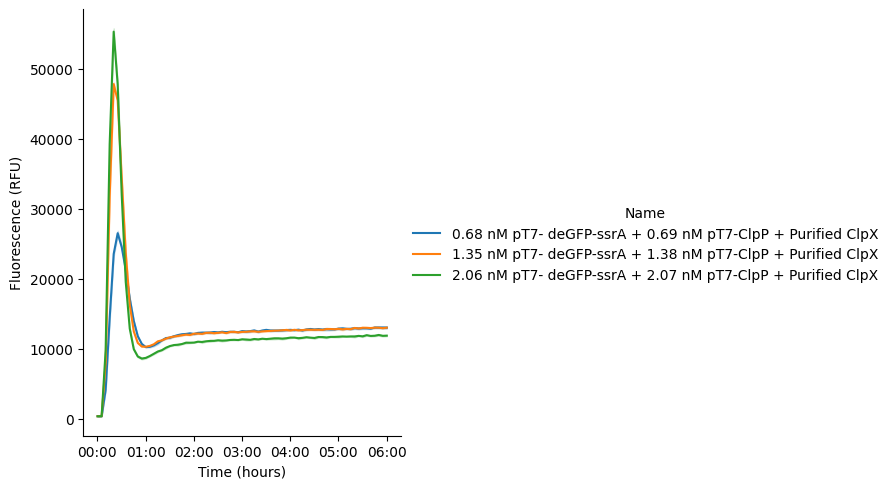

In [3]:
#| label: 20260608-gfp-clpp
g = pr.plot_curves(data=data)

## Normalize Data

In [4]:
data = pr.normalize_data_to_controls(data, ctrl_name = '10 uM HPTS')

Control name '10 uM HPTS' not found in data. No normalization applied.


Now replot your curves to see them normalized

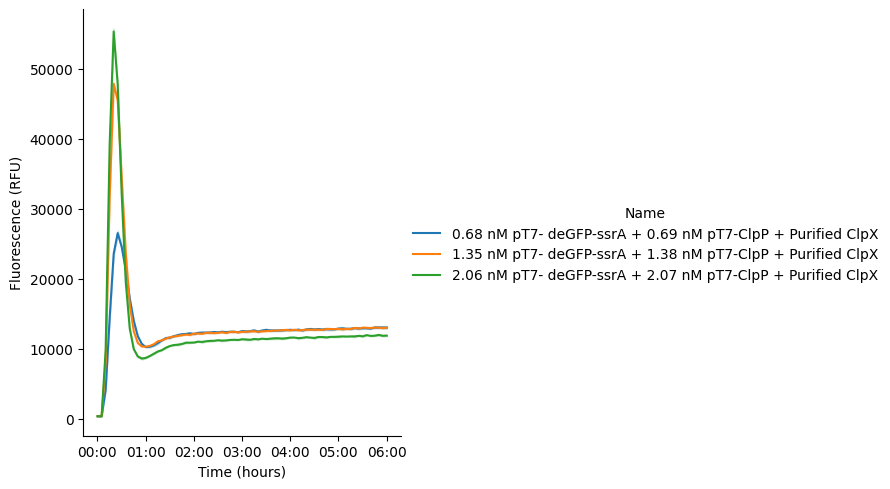

In [5]:
g = pr.plot_curves(data=data)

## Kinetic Analysis
**Metrics extracted:**

  - **Vmax** (`Velocity Max`): Maximum rate of fluorescence increase (slope at inflection point)
  - **Lag time**: Time to reach the exponential phase
  - **Steady-state**: Final fluorescence level and time to reach 95% of asymptote
  - **Drift**: Rate of signal decay or increase after steady-state
  - **R²**: Goodness of fit

In [6]:
# Perform kinetic analysis using sigmoid_drift model
kinetics = pr.kinetic_analysis(
    data=data,
    group_by=['Well','Name'],  # Group by experimental condition
)

kinetics.head()

`Type` column not found in data. All data will be used for kinetic analysis.


Calculating Kinetics


Velocity  \
                                                                             Time   
Well Name                                                                           
A5   0.68 nM pT7- deGFP-ssrA + 0.69 nM pT7-ClpP + Pu... 0 days 00:10:25.729752925   
A6   1.35 nM pT7- deGFP-ssrA + 1.38 nM pT7-ClpP + Pu...           0 days 00:00:00   
A7   2.06 nM pT7- deGFP-ssrA + 2.07 nM pT7-ClpP + Pu...           0 days 00:00:00   
B5   0.68 nM pT7- deGFP-ssrA + 0.69 nM pT7-ClpP + Pu... 0 days 00:10:24.455472816   
B6   1.35 nM pT7- deGFP-ssrA + 1.38 nM pT7-ClpP + Pu...           0 days 00:00:00   

                                                                             \
                                                           Data         Max   
Well Name                                                                     
A5   0.68 nM pT7- deGFP-ssrA + 0.69 nM pT7-ClpP + Pu... 7094.15  1297901.53   
A6   1.35 nM pT7- deGFP-ssrA + 1.38 nM pT7-ClpP + Pu... 5604.51 28022572.61   
A7   2.06 nM pT7- deGFP-ssrA + 2.07 nM pT7-ClpP + Pu... 4869.61 24348066.99   
B5   0.68 nM pT7- deGFP-ssrA + 0.69 nM pT7-ClpP + Pu... 7024.47  1590246.11   
B6   1.35 nM pT7- deGFP-ssrA + 1.38 nM pT7-ClpP + Pu... 5618.85 28094249.41   

                                                                              Lag  \
                                                                             Time   
Well Name                                                                           
A5   0.68 nM pT7- deGFP-ssrA + 0.69 nM pT7-ClpP + Pu... 0 days 00:10:06.052657339   
A6   1.35 nM pT7- deGFP-ssrA + 1.38 nM pT7-ClpP + Pu...  -1 days +23:59:59.280000   
A7   2.06 nM pT7- deGFP-ssrA + 2.07 nM pT7-ClpP + Pu...  -1 days +23:59:59.280000   
B5   0.68 nM pT7- deGFP-ssrA + 0.69 nM pT7-ClpP + Pu... 0 days 00:10:08.553474742   
B6   1.35 nM pT7- deGFP-ssrA + 1.38 nM pT7-ClpP + Pu...  -1 days +23:59:59.280000   

                                                                 \
                                                           Data   
Well Name                                                         
A5   0.68 nM pT7- deGFP-ssrA + 0.69 nM pT7-ClpP + Pu... 2022.91   
A6   1.35 nM pT7- deGFP-ssrA + 1.38 nM pT7-ClpP + Pu... 6226.23   
A7   2.06 nM pT7- deGFP-ssrA + 2.07 nM pT7-ClpP + Pu... 7440.40   
B5   0.68 nM pT7- deGFP-ssrA + 0.69 nM pT7-ClpP + Pu... 1999.98   
B6   1.35 nM pT7- deGFP-ssrA + 1.38 nM pT7-ClpP + Pu... 6269.55   

                                                                     Steady State  \
                                                                             Time   
Well Name                                                                           
A5   0.68 nM pT7- deGFP-ssrA + 0.69 nM pT7-ClpP + Pu... 0 days 00:10:54.698755184   
A6   1.35 nM pT7- deGFP-ssrA + 1.38 nM pT7-ClpP + Pu... 0 days 00:00:01.059998032   
A7   2.06 nM pT7- deGFP-ssrA + 2.07 nM pT7-ClpP + Pu... 0 days 00:00:01.059998032   
B5   0.68 nM pT7- deGFP-ssrA + 0.69 nM pT7-ClpP + Pu... 0 days 00:10:47.866703098   
B6   1.35 nM pT7- deGFP-ssrA + 1.38 nM pT7-ClpP + Pu... 0 days 00:00:01.059998032   

                                                                  \
                                                            Data   
Well Name                                                          
A5   0.68 nM pT7- deGFP-ssrA + 0.69 nM pT7-ClpP + Pu... 13478.88   
A6   1.35 nM pT7- deGFP-ssrA + 1.38 nM pT7-ClpP + Pu... 10648.58   
A7   2.06 nM pT7- deGFP-ssrA + 2.07 nM pT7-ClpP + Pu...  9252.27   
B5   0.68 nM pT7- deGFP-ssrA + 0.69 nM pT7-ClpP + Pu... 13346.49   
B6   1.35 nM pT7- deGFP-ssrA + 1.38 nM pT7-ClpP + Pu... 10675.81   

                                                                                                       Fit  \
                                                                                                    params   
Well Name                                                                                      

## Visualize Fits on Individual Wells

`Type` column not found in data. All data will be used for kinetic analysis.


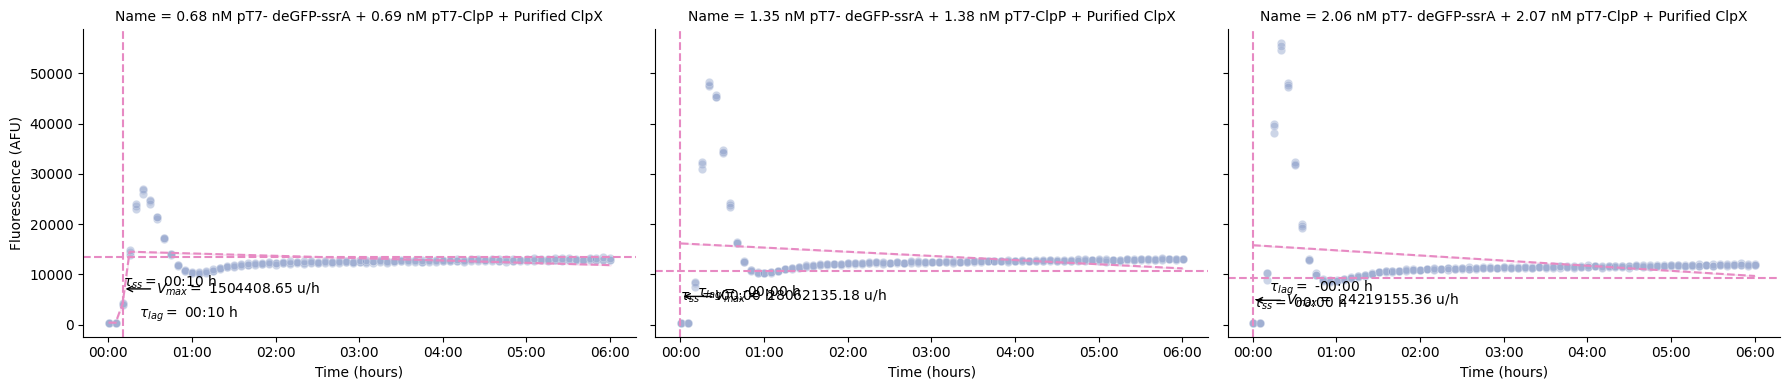

In [7]:
# Plot kinetic fits 
g = pr.plot_kinetics(data, kinetics=kinetics)

## Summary Plots

`Type` column not found in data. All data will be used for kinetic analysis.


Calculating Kinetics


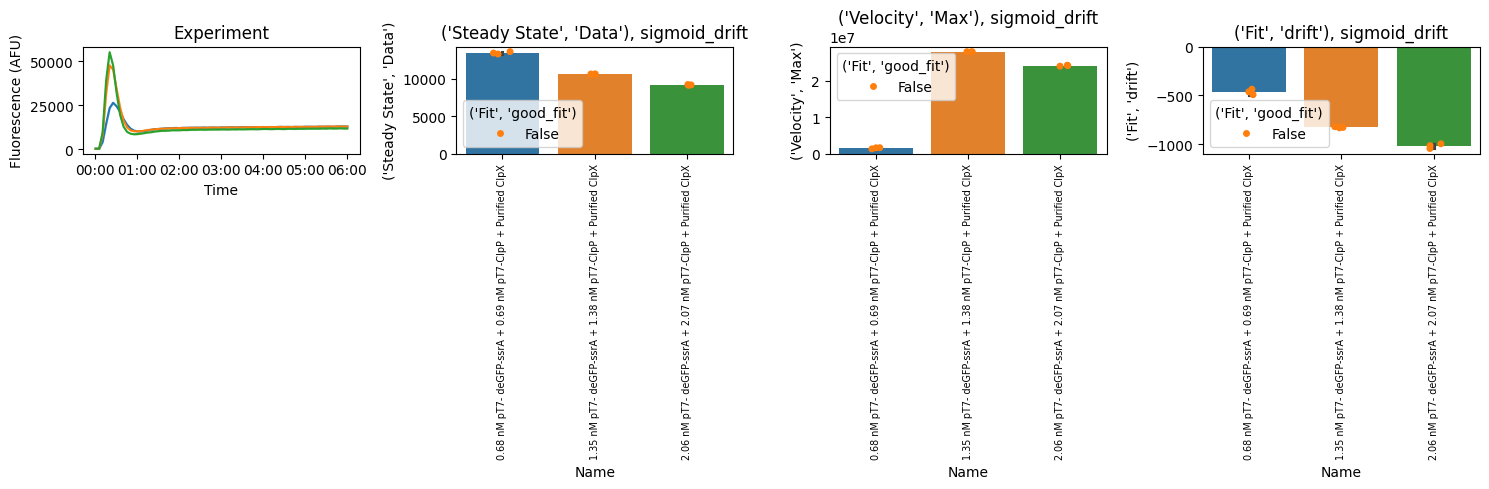

In [8]:
g = pr.plot_summary(data)
# g.savefig("summary.png", dpi=300)

---

## Key Metrics Explained

### 1. **Steady-State Level** (`Steady State, Data`)
- The final fluorescence value reached by the reaction
- Represents the total amount of protein produced
- Higher values indicate greater expression yield

### 2. **Maximum Velocity** (`Velocity, Max`)
- The steepest slope of the fluorescence curve (at the inflection point)
- Units: RFU per second
- Reflects the peak rate of protein synthesis
- Sensitive to enzyme activity, substrate availability, and reaction conditions

### 3. **Lag Time** (`Lag, Time`)
- Time before exponential fluorescence increase begins
- May reflect time for ribosome assembly or initial translation steps
- Shorter lag times suggest faster reaction initiation

### 4. **Drift** (`Fit, drift`)
- Rate of fluorescence change after reaching steady-state
- Positive drift: continued synthesis or aggregation
- Negative drift: photobleaching, protein degradation, or quenching
- Units: RFU per second

### 5. **R² Value** (`Fit, R^2`)
- Goodness of fit (0 to 1, higher is better)
- R² > 0.98 indicates excellent fit
- Poor fits may indicate noisy data, overflow errors, or non-sigmoid kinetics

---

## Tips and Troubleshooting

- **Overflow errors:** Wells with `OVRFLW` or `NaN` values are automatically excluded from fitting
- **Poor fits (low R²):** Inspect raw curves for anomalies (bubbles, evaporation, pipetting errors)
- **Drift:** Sometimes seen in kinetics curves; use `sigmoid_drift` model
- **Multiple replicates:** Always include technical replicates and report error bars
- **Comparing conditions:** Normalize or blank data consistently across all samples

---

## Next Steps

- Export kinetics results: `pr.export_kinetics(kinetics, 'results.csv')`
- Statistical analysis: Use `scipy.stats` or `statsmodels` for ANOVA/t-tests
- Parameter optimization: Vary Mg²⁺, K⁺, or other conditions to maximize Vmax or steady-state
- Mechanistic modeling: Fit ODE models to extract biological rate constants